In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:
!pip -q install diffusers transformers accelerate safetensors

Using device: cuda
Loading Stable Diffusion 1.5...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Generating image...


  0%|          | 0/20 [00:00<?, ?it/s]

SUCCESS! Image saved to: /content/generated_images/first_driving_scene.png


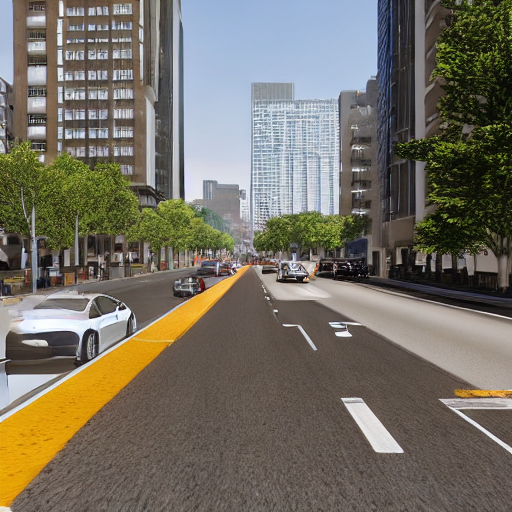

In [ ]:

import torch
from pathlib import Path
from diffusers import StableDiffusionPipeline
from IPython.display import display

# Select the available device
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

print("Using device:", device)
print("Loading Stable Diffusion 1.5...")

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype,
    use_safetensors=True,
)

pipe = pipe.to(device)

prompt = (
    "Photorealistic front dashboard camera view of an autonomous car "
    "driving on an urban road, cars ahead, clear lane markings, "
    "buildings along the street, realistic daylight, natural colors, "
    "real-world traffic scene, high detail"
)

generator = torch.Generator(device=device).manual_seed(42)

print("Generating image...")

with torch.inference_mode():
    result = pipe(
        prompt=prompt,
        negative_prompt=(
            "cartoon, illustration, blurry, distorted cars, "
            "unrealistic road, text, watermark"
        ),
        width=512,
        height=512,
        num_inference_steps=20,
        guidance_scale=7.0,
        generator=generator,
    )

image = result.images[0]

output_dir = Path("/content/generated_images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "first_driving_scene.png"
image.save(output_path)

print("SUCCESS! Image saved to:", output_path)
display(image)


In [ ]:
from google.colab import files

files.download("/content/generated_images/first_driving_scene.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "/content/synthetic_driving_dataset",
    "zip",
    "/content/synthetic_driving_dataset",
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import csv
from pathlib import Path
import torch
from diffusers import StableDiffusionPipeline
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

if device != "cuda":
    raise RuntimeError(
        "GPU not detected. In Colab, select Runtime > Change runtime type > T4 GPU."
    )

root = Path("/content/synthetic_driving_dataset")
root.mkdir(parents=True, exist_ok=True)

scenarios = {
    "daytime": (
        "Photorealistic dashboard camera view of a car driving on an "
        "urban road, visible cars, clear lane markings, buildings, "
        "natural bright daylight, realistic traffic scene"
    ),
    "night": (
        "Photorealistic dashboard camera view of a car driving on an "
        "urban road at night, visible vehicles, streetlights, headlights, "
        "realistic nighttime traffic"
    ),
    "rain": (
        "Photorealistic dashboard camera view of a car driving on a wet "
        "urban road during rain, wet asphalt, reflections, visible cars, "
        "realistic rainy traffic scene"
    ),
    "fog": (
        "Photorealistic dashboard camera view of a car driving on an "
        "urban road in fog, reduced visibility, vehicles ahead, "
        "road markings, realistic foggy traffic scene"
    ),
}

print("Loading model on", device)

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=dtype,
    use_safetensors=True,
).to(device)

pipe.enable_attention_slicing()

metadata_path = root / "metadata.csv"
fieldnames = [
    "filename", "condition", "prompt", "seed", "width", "height"
]

# Read existing metadata, if present.
# Keep existing records and don't generate over existing files.
metadata_by_filename = {}
if metadata_path.exists():
    with open(metadata_path, newline="", encoding="utf-8") as file:
        for row in csv.DictReader(file):
            metadata_by_filename[row["filename"]] = row

negative_prompt = (
    "cartoon, blurry, distorted vehicles, unrealistic road, "
    "text, watermark, malformed cars"
)

for condition_index, (condition, base_prompt) in enumerate(scenarios.items()):
    condition_dir = root / condition
    condition_dir.mkdir(parents=True, exist_ok=True)

    # Keep the original 3 images; add images 004 through 025.
    for index in range(4, 26):
        filename = f"{condition}_{index:03d}.png"
        output_path = condition_dir / filename

        seed = 2000 + condition_index * 1000 + index

        # Reuse existing image files safely.
        if output_path.exists():
            print("Already exists; preserving:", output_path)
        else:
            # Small prompt variations help introduce scene diversity.
            variations = [
                "different vehicles and road layout",
                "a wide urban street with several cars ahead",
                "a realistic intersection in the distance",
                "suburban buildings along the roadway",
                "a multi-lane road with clear perspective",
                "moderate traffic with varied vehicle spacing",
            ]
            variation = variations[(index - 4) % len(variations)]
            prompt = (
                base_prompt
                + ", "
                + variation
                + ", realistic proportions, natural camera perspective"
            )

            generator = torch.Generator(device=device).manual_seed(seed)
            print(f"Generating {condition}: {index}/25")

            with torch.inference_mode():
                result = pipe(
                    prompt=prompt,
                    negative_prompt=negative_prompt,
                    width=512,
                    height=512,
                    num_inference_steps=20,
                    guidance_scale=7.0,
                    generator=generator,
                )

            result.images[0].save(output_path)
            print("Saved:", output_path)

        # Store metadata for this new filename.
        prompt_for_metadata = (
            base_prompt
            + ", "
            + [
                "different vehicles and road layout",
                "a wide urban street with several cars ahead",
                "a realistic intersection in the distance",
                "suburban buildings along the roadway",
                "a multi-lane road with clear perspective",
                "moderate traffic with varied vehicle spacing",
            ][(index - 4) % 6]
            + ", realistic proportions, natural camera perspective"
        )

        metadata_by_filename[filename] = {
            "filename": filename,
            "condition": condition,
            "prompt": prompt_for_metadata,
            "seed": seed,
            "width": 512,
            "height": 512,
        }

        # Save updated metadata after each image.
        with open(metadata_path, "w", newline="", encoding="utf-8") as file:
            writer = csv.DictWriter(file, fieldnames=fieldnames)
            writer.writeheader()
            writer.writerows(metadata_by_filename.values())

print("\nGeneration finished.")

for condition in scenarios:
    count = len(list((root / condition).glob("*.png")))
    print(f"{condition}: {count} image files")

print("Metadata saved:", metadata_path)
print("Dataset folder:", root)



Loading model on cuda


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

...

Saved: /content/synthetic_driving_dataset/fog/fog_023.png
Generating fog: 24/25


  0%|          | 0/20 [00:00<?, ?it/s]

Saved: /content/synthetic_driving_dataset/fog/fog_024.png
Generating fog: 25/25


  0%|          | 0/20 [00:00<?, ?it/s]

Saved: /content/synthetic_driving_dataset/fog/fog_025.png

Generation finished.
daytime: 22 image files
night: 22 image files
rain: 22 image files
fog: 22 image files
Metadata saved: /content/synthetic_driving_dataset/metadata.csv
Dataset folder: /content/synthetic_driving_dataset


In [ ]:
from pathlib import Path

root = Path("/content/synthetic_driving_dataset")

total = 0
for condition in ["daytime", "night", "rain", "fog"]:
    count = len(list((root / condition).glob("*.png")))
    total += count
    print(f"{condition}: {count} images")

print("TOTAL:", total)
print("Metadata exists:", (root / "metadata.csv").exists())

daytime: 0 images
night: 0 images
rain: 0 images
fog: 0 images
TOTAL: 0
Metadata exists: False


In [ ]:

import shutil
from google.colab import files

root = "/content/synthetic_driving_dataset"

archive_path = shutil.make_archive(
    "/content/synthetic_driving_dataset",
    "zip",
    root_dir=root
)

files.download(archive_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

for folder in [
    Path("/content"),
    Path("/content/generated_images"),
    Path("/content/generated_extra"),
    Path("/content/synthetic_driving_dataset"),
]:
    print(f"\nChecking: {folder}")
    if folder.exists():
        for item in list(folder.iterdir())[:15]:
            print(" ", item.name)
    else:
        print("  Folder does not exist")


Checking: /content
  .config
  sample_data

Checking: /content/generated_images
  Folder does not exist

Checking: /content/generated_extra
  Folder does not exist

Checking: /content/synthetic_driving_dataset
  Folder does not exist


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive_folder = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset"
)
drive_folder.mkdir(parents=True, exist_ok=True)

print("Dataset folder ready:", drive_folder)
print("Google Drive mounted:", Path("/content/drive/MyDrive").exists())

Dataset folder ready: /content/drive/MyDrive/synthetic_driving_dataset
Google Drive mounted: True


In [ ]:


import csv
from pathlib import Path
import torch
from diffusers import StableDiffusionPipeline

# Save directly to persistent Google Drive storage
root = Path("/content/drive/MyDrive/synthetic_driving_dataset")
root.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not detected. Select Runtime > Change runtime type > T4 GPU."
    )

device = "cuda"
dtype = torch.float16

scenarios = {
    "daytime": "urban road in bright daylight, cars ahead, clear lane markings, buildings",
    "night": "urban road at night, cars ahead, headlights, streetlights, realistic traffic",
    "rain": "wet urban road during rain, cars ahead, wet asphalt and reflections",
    "fog": "foggy urban road, reduced visibility, cars ahead, visible road markings",
}

fieldnames = ["filename", "condition", "prompt", "seed", "width", "height"]
metadata_path = root / "metadata.csv"

# Load existing metadata so reruns can resume safely.
metadata = {}
if metadata_path.exists():
    with open(metadata_path, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            metadata[row["filename"]] = row

print("Loading Stable Diffusion...")
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=dtype,
    use_safetensors=True,
).to(device)
pipe.enable_attention_slicing()

negative_prompt = (
    "cartoon, illustration, blurry, distorted vehicles, "
    "unrealistic road, text, watermark"
)

for condition_index, (condition, description) in enumerate(scenarios.items()):
    folder = root / condition
    folder.mkdir(parents=True, exist_ok=True)

    # Generate 25 images for each condition.
    for index in range(1, 26):
        filename = f"{condition}_{index:03d}.png"
        path = folder / filename

        prompt = (
            "Photorealistic front dashboard camera view for autonomous driving, "
            f"{description}, realistic road perspective, natural details, "
            f"variation {index}"
        )
        seed = 30000 + condition_index * 1000 + index

        if path.exists():
            print("Keeping existing image:", filename)
        else:
            generator = torch.Generator(device=device).manual_seed(seed)
            print(f"Generating {condition}: {index}/25")

            with torch.inference_mode():
                result = pipe(
                    prompt=prompt,
                    negative_prompt=negative_prompt,
                    width=512,
                    height=512,
                    num_inference_steps=20,
                    guidance_scale=7.0,
                    generator=generator,
                )

            result.images[0].save(path)

        # Record metadata only for an image that exists.
        if path.exists():
            metadata[filename] = {
                "filename": filename,
                "condition": condition,
                "prompt": prompt,
                "seed": seed,
                "width": 512,
                "height": 512,
            }

        # Persist progress after every image.
        with open(metadata_path, "w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writeheader()
            writer.writerows(metadata.values())

print("\nGeneration/check complete.")
total = 0
for condition in scenarios:
    count = len(list((root / condition).glob("*.png")))
    total += count
    print(f"{condition}: {count} images")

print("Total image files:", total)
print("Metadata:", metadata_path)
print("Saved in Google Drive:", root)




Loading Stable Diffusion...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

...

Generating fog: 24/25


  0%|          | 0/20 [00:00<?, ?it/s]

Generating fog: 25/25


  0%|          | 0/20 [00:00<?, ?it/s]


Generation/check complete.
daytime: 25 images
night: 25 images
rain: 25 images
fog: 25 images
Total image files: 100
Metadata: /content/drive/MyDrive/synthetic_driving_dataset/metadata.csv
Saved in Google Drive: /content/drive/MyDrive/synthetic_driving_dataset


In [ ]:
from google.colab import files

files.download("/content/synthetic_driving_dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil

source = "/content/drive/MyDrive/synthetic_driving_dataset"
zip_path = shutil.make_archive(
    "/content/synthetic_driving_dataset",
    "zip",
    root_dir=source,
)

print("ZIP created:", zip_path)

ZIP created: /content/synthetic_driving_dataset.zip


In [ ]:

from pathlib import Path

drive_folder = Path("/content/drive/MyDrive/synthetic_driving_dataset")
zip_path = drive_folder / "kitti_training_subset.zip"

print("Drive folder exists:", drive_folder.exists())
print("ZIP file exists:", zip_path.exists())

if zip_path.exists():
    print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))
else:
    print("Expected file:", zip_path)
    print("Check the folder name and uploaded filename.")


Drive folder exists: True
ZIP file exists: True
ZIP size (MB): 24.67


In [ ]:

from pathlib import Path
import zipfile

drive_folder = Path("/content/drive/MyDrive/synthetic_driving_dataset")
zip_path = drive_folder / "kitti_training_subset.zip"
extract_dir = Path("/content/kitti_training_subset")

if not zip_path.exists():
    raise FileNotFoundError(f"ZIP file not found: {zip_path}")

extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_dir)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
images = [
    path for path in extract_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

print("Extracted image count:", len(images))
print("Training folder:", extract_dir)
print("Example image:", images[0] if images else "No images found")

assert len(images) >= 100, "Too few images found. Check the ZIP contents."


Extracted image count: 500
Training folder: /content/kitti_training_subset
Example image: /content/kitti_training_subset/kitti_0360.png


In [ ]:

%pip install -q diffusers transformers accelerate peft safetensors


In [ ]:

import torch
from pathlib import Path
from PIL import Image

assert torch.cuda.is_available(), "GPU is not enabled."

image_dir = Path("/content/kitti_training_subset")
image_paths = sorted(
    p for p in image_dir.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

assert len(image_paths) == 500, f"Expected 500 images, found {len(image_paths)}"

# Verify that one image opens correctly.
with Image.open(image_paths[0]) as image:
    print("Example image size:", image.size)
    print("Example image mode:", image.mode)

gpu = torch.cuda.get_device_name(0)
total_memory_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)

print("GPU:", gpu)
print("GPU memory:", round(total_memory_gb, 2), "GB")
print("Verified training images:", len(image_paths))


Example image size: (1224, 370)
Example image mode: RGB
GPU: Tesla T4
GPU memory: 14.56 GB
Verified training images: 500


In [ ]:

from pathlib import Path
from PIL import Image
import json

source_dir = Path("/content/kitti_training_subset")
train_dir = Path("/content/driving_lora_dataset")
train_dir.mkdir(parents=True, exist_ok=True)

extensions = {".jpg", ".jpeg", ".png", ".bmp"}
image_paths = sorted(
    p for p in source_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

manifest = []

for index, path in enumerate(image_paths, start=1):
    output_path = train_dir / f"image_{index:04d}.jpg"

    with Image.open(path) as image:
        image = image.convert("RGB")
        image.save(output_path, "JPEG", quality=95)

    manifest.append({
        "file_name": output_path.name,
        "text": (
            "photograph from a forward-facing vehicle camera, "
            "realistic road scene, vehicles, road markings, "
            "natural outdoor lighting"
        )
    })

with open(train_dir / "metadata.jsonl", "w", encoding="utf-8") as f:
    for item in manifest:
        f.write(json.dumps(item) + "\n")

print("Prepared images:", len(manifest))
print("Dataset directory:", train_dir)
print("Caption example:", manifest[0]["text"])
print("Metadata file:", train_dir / "metadata.jsonl")


Prepared images: 500
Dataset directory: /content/driving_lora_dataset
Caption example: photograph from a forward-facing vehicle camera, realistic road scene, vehicles, road markings, natural outdoor lighting
Metadata file: /content/driving_lora_dataset/metadata.jsonl


In [ ]:

from pathlib import Path
import torch

assert torch.cuda.is_available(), "Enable the GPU runtime first."

TRAIN_DIR = Path("/content/driving_lora_dataset")
OUTPUT_DIR = Path("/content/driving-lora-output")

assert (TRAIN_DIR / "metadata.jsonl").exists(), "Dataset metadata is missing."

with open(TRAIN_DIR / "metadata.jsonl", encoding="utf-8") as f:
    dataset_count = sum(1 for line in f if line.strip())

config = {
    "pretrained_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
    "train_data_dir": str(TRAIN_DIR),
    "output_dir": str(OUTPUT_DIR),
    "resolution": 512,
    "train_batch_size": 1,
    "gradient_accumulation_steps": 4,
    "learning_rate": 1e-4,
    "max_train_steps": 500,
    "rank": 8,
    "mixed_precision": "fp16",
    "gradient_checkpointing": True,
    "seed": 42,
}

print("Dataset images:", dataset_count)
print("GPU:", torch.cuda.get_device_name(0))
print("Configuration:")
for key, value in config.items():
    print(f"  {key}: {value}")


Dataset images: 500
GPU: Tesla T4
Configuration:
  pretrained_model: stable-diffusion-v1-5/stable-diffusion-v1-5
  train_data_dir: /content/driving_lora_dataset
  output_dir: /content/driving-lora-output
  resolution: 512
  train_batch_size: 1
  gradient_accumulation_steps: 4
  learning_rate: 0.0001
  max_train_steps: 500
  rank: 8
  mixed_precision: fp16
  gradient_checkpointing: True
  seed: 42


In [ ]:

import json

config_path = Path("/content/driving_lora_config.json")
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

print("Configuration saved:", config_path)


Configuration saved: /content/driving_lora_config.json


In [ ]:

%cd /content
!git clone --depth 1 https://github.com/huggingface/diffusers.git


/content
Cloning into 'diffusers'...
remote: Enumerating objects: 3261, done.
remote: Counting objects: 100% (3261/3261), done.
remote: Compressing objects: 100% (2438/2438), done.
remote: Total 3261 (delta 1164), reused 1392 (delta 784), pack-reused 0 (from 0)
Receiving objects: 100% (3261/3261), 10.62 MiB | 9.93 MiB/s, done.
Resolving deltas: 100% (1164/1164), done.


In [ ]:

from pathlib import Path

script = Path(
    "/content/diffusers/examples/text_to_image/train_text_to_image_lora.py"
)

print("Training script exists:", script.exists())

if script.exists():
    print("Script size:", round(script.stat().st_size / 1024, 1), "KB")
else:
    print("The script was not found at the expected path.")


Training script exists: True
Script size: 42.2 KB


In [ ]:

%cd /content/diffusers

!python examples/text_to_image/train_text_to_image_lora.py --help


/content/diffusers
Traceback (most recent call last):
  File "/content/diffusers/examples/text_to_image/train_text_to_image_lora.py", line 64, in <module>
    check_min_version("0.41.0.dev0")
    ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/diffusers/utils/__init__.py", line 175, in check_min_version
    raise ImportError(error_message)
ImportError: This example requires a source install from HuggingFace diffusers (see `https://huggingface.co/docs/diffusers/installation#install-from-source`), but the version found is 0.40.0.



In [ ]:

%cd /content/diffusers
%pip install -q -e .


/content/diffusers
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for diffusers (pyproject.toml) ... done


In [ ]:

import importlib.metadata
import diffusers
import torch

try:
    version = importlib.metadata.version("diffusers")
except importlib.metadata.PackageNotFoundError:
    version = "Package metadata not found"

print("Diffusers package version:", version)
print("Diffusers module location:", getattr(diffusers, "__file__", "unknown"))
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Diffusers package version: 0.41.0.dev0
Diffusers module location: None
GPU available: True
GPU: Tesla T4


In [ ]:

%pip uninstall -y torchao



Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:

import torch
from diffusers import StableDiffusionPipeline, UNet2DConditionModel
print("Diffusers core imports succeeded.")
print("GPU available:", torch.cuda.is_available())


ImportError: cannot import name 'StableDiffusionPipeline' from 'diffusers' (unknown location)

In [ ]:

import sys
import importlib.util
import importlib.metadata

print("Python:", sys.version)
print("Python executable:", sys.executable)

spec = importlib.util.find_spec("diffusers")
print("Diffusers module spec:", spec)
print("Diffusers module path:", spec.origin if spec else "Not found")

for package in ["diffusers", "torch", "torchvision", "transformers", "peft", "accelerate", "torchao"]:
    try:
        print(f"{package}: {importlib.metadata.version(package)}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package}: not installed")


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Python executable: /usr/bin/python3
Diffusers module spec: ModuleSpec(name='diffusers', loader=<_frozen_importlib_external.NamespaceLoader object at 0x7f4bdf4af6f0>, submodule_search_locations=_NamespacePath(['/content/diffusers']))
Diffusers module path: None
diffusers: 0.41.0.dev0
torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
transformers: 5.18.0
peft: 0.21.1
accelerate: 1.15.0
torchao: not installed


In [ ]:

from pathlib import Path

repo = Path("/content/diffusers")

for path in [
    repo / "src" / "diffusers" / "__init__.py",
    repo / "src" / "diffusers" / "pipelines" / "__init__.py",
    repo / "examples" / "text_to_image" / "train_text_to_image_lora.py",
]:
    print(f"{path}: exists={path.exists()}")


/content/diffusers/src/diffusers/__init__.py: exists=True
/content/diffusers/src/diffusers/pipelines/__init__.py: exists=True
/content/diffusers/examples/text_to_image/train_text_to_image_lora.py: exists=True


In [ ]:

%cd /content/diffusers
%pip install --no-deps --force-reinstall -e /content/diffusers


/content/diffusers
Obtaining file:///content/diffusers
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for diffusers (pyproject.toml) ... done
  Created wheel for diffusers: filename=diffusers-0.41.0.dev0-0.editable-py3-none-any.whl size=11470 sha256=3191664e6e49ebfbb8895329e959ec2189ce2ce6da9716372d5a8a41ab029f9c
  Stored in directory: /tmp/pip-ephem-wheel-cache-hr5o78c0/wheels/ce/09/f1/683b43f8a222a091c8294e229524928cfaa64c9af69cd211b8
Successfully built diffusers
  Attempting uninstall: diffusers
    Found existing installation: diffusers 0.41.0.dev0
    Uninstalling diffusers-0.41.0.dev0:
      Successfully uninstalled diffusers-0.41.0.dev0


In [ ]:

import diffusers
import torch

print("Diffusers version:", getattr(diffusers, "__version__", "unknown"))
print("Diffusers module file:", getattr(diffusers, "__file__", "unknown"))
print("GPU available:", torch.cuda.is_available())

from diffusers import StableDiffusionPipeline, UNet2DConditionModel
print("Core imports succeeded.")


Diffusers version: 0.41.0.dev0
Diffusers module file: /content/diffusers/src/diffusers/__init__.py
GPU available: True
Core imports succeeded.


In [ ]:

%cd /content/diffusers
!python examples/text_to_image/train_text_to_image_lora.py --help


/content/diffusers
usage: train_text_to_image_lora.py [-h]
                                   --pretrained_model_name_or_path PRETRAINED_MODEL_NAME_OR_PATH
                                   [--revision REVISION] [--variant VARIANT]
                                   [--dataset_name DATASET_NAME]
                                   [--dataset_config_name DATASET_CONFIG_NAME]
                                   [--train_data_dir TRAIN_DATA_DIR]
                                   [--image_column IMAGE_COLUMN]
                                   [--caption_column CAPTION_COLUMN]
                                   [--validation_prompt VALIDATION_PROMPT]
                                   [--num_validation_images NUM_VALIDATION_IMAGES]
                                   [--validation_epochs VALIDATION_EPOCHS]
                                   [--max_train_samples MAX_TRAIN_SAMPLES]
                                   [--output_dir OUTPUT_DIR]
                                   [--cache_dir CAC

In [ ]:

from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

drive_output = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/lora_output"
)
drive_output.mkdir(parents=True, exist_ok=True)

train_dir = Path("/content/driving_lora_dataset")
metadata_path = train_dir / "metadata.jsonl"

print("Training data exists:", train_dir.exists())
print("Metadata exists:", metadata_path.exists())
print("Output folder:", drive_output)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data exists: True
Metadata exists: True
Output folder: /content/drive/MyDrive/synthetic_driving_dataset/lora_output


In [ ]:

import json

metadata_path = Path("/content/driving_lora_dataset/metadata.jsonl")

with open(metadata_path, encoding="utf-8") as f:
    first_record = json.loads(next(f))

print(first_record)


{'file_name': 'image_0001.jpg', 'text': 'photograph from a forward-facing vehicle camera, realistic road scene, vehicles, road markings, natural outdoor lighting'}


In [ ]:


%cd /content/diffusers

!accelerate launch --mixed_precision=fp16 examples/text_to_image/train_text_to_image_lora.py \
  --pretrained_model_name_or_path="stable-diffusion-v1-5/stable-diffusion-v1-5" \
  --train_data_dir="/content/driving_lora_dataset" \
  --image_column="image" \
  --caption_column="text" \
  --output_dir="/content/drive/MyDrive/synthetic_driving_dataset/lora_output" \
  --resolution=512 \
  --center_crop \
  --train_batch_size=1 \
  --gradient_accumulation_steps=4 \
  --max_train_steps=20 \
  --learning_rate=1e-4 \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --rank=8 \
  --mixed_precision="fp16" \
  --gradient_checkpointing \
  --dataloader_num_workers=0 \
  --checkpointing_steps=20 \
  --checkpoints_total_limit=1 \
  --seed=42



/content/diffusers
The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_processes` was set to a value of `1`
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
10/18/2026 10:49:00 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
10/18/2026 10:49:00 - INFO - httpx - HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
10/18/2026 10:49:00 - INFO - httpx - HTTP Request: HEAD https://huggingface.co

In [ ]:
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/lora_output"
)

print("Output folder exists:", output_dir.exists())

if output_dir.exists():
    for item in sorted(output_dir.rglob("*")):
        if item.is_file():
            print(f"{item.name} — {item.stat().st_size / 1024:.1f} KB")

Output folder exists: True
optimizer.bin — 12666.0 KB
pytorch_lora_weights.safetensors — 6264.1 KB
random_states_0.pkl — 14.5 KB
scaler.pt — 1.4 KB
scheduler.bin — 1.4 KB
events.out.tfevents.1792320596.a06fd1309495.5877.1 — 2.4 KB
hparams.yml — 1.2 KB
events.out.tfevents.1792320596.a06fd1309495.5877.0 — 1.0 KB
pytorch_lora_weights.safetensors — 6264.6 KB


/content/diffusers/src/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/n

  0%|          | 0/20 [00:00<?, ?it/s]

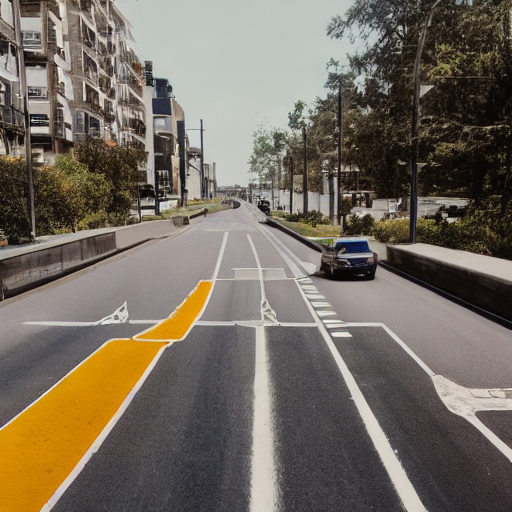

Saved test image to: /content/drive/MyDrive/synthetic_driving_dataset/lora_test.png


In [ ]:

import torch
from diffusers import StableDiffusionPipeline
from pathlib import Path
from IPython.display import display

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
lora_dir = "/content/drive/MyDrive/synthetic_driving_dataset/lora_output"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    safety_checker=None,
).to("cuda")

pipe.load_lora_weights(lora_dir)

prompt = (
    "photorealistic forward-facing dashcam photograph of a road, "
    "cars ahead, clear lane markings, realistic urban driving scene, "
    "natural daylight, documentary photography"
)

generator = torch.Generator(device="cuda").manual_seed(42)

image = pipe(
    prompt,
    num_inference_steps=20,
    guidance_scale=7.0,
    generator=generator,
).images[0]

display(image)

test_path = "/content/drive/MyDrive/synthetic_driving_dataset/lora_test.png"
image.save(test_path)
print("Saved test image to:", test_path)


In [ ]:

%cd /content/diffusers

!accelerate launch --mixed_precision=fp16 examples/text_to_image/train_text_to_image_lora.py \
  --pretrained_model_name_or_path="stable-diffusion-v1-5/stable-diffusion-v1-5" \
  --train_data_dir="/content/driving_lora_dataset" \
  --image_column="image" \
  --caption_column="text" \
  --output_dir="/content/drive/MyDrive/synthetic_driving_dataset/lora_500_steps" \
  --resolution=512 \
  --center_crop \
  --train_batch_size=1 \
  --gradient_accumulation_steps=4 \
  --max_train_steps=500 \
  --learning_rate=1e-4 \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --rank=8 \
  --mixed_precision="fp16" \
  --gradient_checkpointing \
  --dataloader_num_workers=0 \
  --checkpointing_steps=100 \
  --checkpoints_total_limit=2 \
  --seed=42


/content/diffusers
The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_processes` was set to a value of `1`
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
10/18/2026 10:53:17 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
10/18/2026 10:53:17 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Re

In [ ]:

import torch
from pathlib import Path
from diffusers import StableDiffusionPipeline
from IPython.display import display

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
lora_dir = "/content/drive/MyDrive/synthetic_driving_dataset/lora_500_steps"
output_root = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/lora_generated"
)

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    safety_checker=None,
).to("cuda")

pipe.load_lora_weights(lora_dir)
pipe.set_progress_bar_config(disable=False)

conditions = {
    "daytime": (
        "photorealistic forward-facing dashcam photograph of a road, "
        "cars ahead, lane markings, natural daylight"
    ),
    "night": (
        "photorealistic forward-facing dashcam photograph of a road at night, "
        "cars ahead, visible headlights, realistic street lighting"
    ),
    "rain": (
        "photorealistic forward-facing dashcam photograph of a wet road in rain, "
        "cars ahead, reflections on asphalt, overcast weather"
    ),
    "fog": (
        "photorealistic forward-facing dashcam photograph of a foggy road, "
        "cars ahead, reduced visibility, realistic road markings"
    ),
}

total = 0

for condition_index, (condition, prompt) in enumerate(conditions.items()):
    condition_dir = output_root / condition
    condition_dir.mkdir(parents=True, exist_ok=True)

    for i in range(25):
        image_path = condition_dir / f"{condition}_{i+1:03d}.png"

        # Keep existing images if you need to safely resume generation.
        if image_path.exists():
            total += 1
            continue

        generator = torch.Generator(device="cuda").manual_seed(
            1000 + condition_index * 100 + i
        )

        image = pipe(
            prompt,
            num_inference_steps=20,
            guidance_scale=7.0,
            generator=generator,
        ).images[0]

        image.save(image_path)
        total += 1

    print(f"{condition}: {len(list(condition_dir.glob('*.png')))} images saved")

print(f"Total images available: {total}")
print("Output folder:", output_root)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/n

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

...

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

fog: 25 images saved
Total images available: 100
Output folder: /content/drive/MyDrive/synthetic_driving_dataset/lora_generated


In [ ]:

from pathlib import Path

generated_root = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/lora_generated"
)

for condition in ["daytime", "night", "rain", "fog"]:
    folder = generated_root / condition
    images = [
        p for p in folder.iterdir()
        if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
    ] if folder.exists() else []

    print(f"{condition}: {len(images)} images")

print("Total:", sum(
    len([
        p for p in (generated_root / c).glob("*")
        if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
    ])
    for c in ["daytime", "night", "rain", "fog"]
))


daytime: 25 images
night: 25 images
rain: 25 images
fog: 25 images
Total: 100


In [ ]:

from pathlib import Path

checks = {
    "Original FID script": Path("/content/evaluate_fid.py"),
    "Real KITTI images": Path("/content/kitti_training_subset"),
    "LoRA generated images": Path(
        "/content/drive/MyDrive/synthetic_driving_dataset/lora_generated"
    ),
}

for label, path in checks.items():
    print(f"{label}: {'FOUND' if path.exists() else 'NOT FOUND'} — {path}")


Original FID script: NOT FOUND — /content/evaluate_fid.py
Real KITTI images: FOUND — /content/kitti_training_subset
LoRA generated images: FOUND — /content/drive/MyDrive/synthetic_driving_dataset/lora_generated


In [ ]:

%pip install -q torchmetrics torch-fidelity


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 9.5 MB/s eta 0:00:00


In [ ]:

import torch
import torchmetrics
import torch_fidelity

print("PyTorch:", torch.__version__)
print("TorchMetrics:", torchmetrics.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130
TorchMetrics: 1.9.0
CUDA available: True


In [ ]:

import json
import random
from pathlib import Path

import torch
from PIL import Image
from torchmetrics.image.fid import FrechetInceptionDistance
from torchvision import transforms
from tqdm.auto import tqdm

real_root = Path("/content/kitti_training_subset")
generated_root = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/lora_generated"
)
results_root = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/fid_evaluation"
)
results_root.mkdir(parents=True, exist_ok=True)

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

real_files = sorted(
    p for p in real_root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)
generated_files = sorted(
    p for p in generated_root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

print("Real images found:", len(real_files))
print("Generated images found:", len(generated_files))

if len(real_files) < 100:
    raise ValueError("Need at least 100 real images.")
if len(generated_files) != 100:
    raise ValueError(f"Expected 100 generated images, found {len(generated_files)}.")

random.Random(42).shuffle(real_files)
real_sample = sorted(real_files[:100])

# Save the exact reference sample list for repeatable evaluation.
with open(results_root / "real_sample_100.json", "w") as f:
    json.dump([str(p) for p in real_sample], f, indent=2)

device = "cuda" if torch.cuda.is_available() else "cpu"
fid = FrechetInceptionDistance(
    feature=2048,
    normalize=True,
).to(device)

to_tensor = transforms.ToTensor()

def update_fid(files, real=True):
    for path in tqdm(files):
        with Image.open(path) as im:
            image = im.convert("RGB")
            tensor = to_tensor(image).unsqueeze(0).to(device)
            fid.update(tensor, real=real)

update_fid(real_sample, real=True)
update_fid(generated_files, real=False)

score = float(fid.compute().cpu())
result = {
    "experiment": "LoRA fine-tuned",
    "fid": score,
    "real_images": len(real_sample),
    "generated_images": len(generated_files),
    "feature_extractor": "InceptionV3, 2048 features",
    "reference_sample_seed": 42,
    "device": device,
}

with open(results_root / "lora_fid_100v100.json", "w") as f:
    json.dump(result, f, indent=2)

print(json.dumps(result, indent=2))
print("Saved results to:", results_root / "lora_fid_100v100.json")


Real images found: 500
Generated images found: 100


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 308MB/s]


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

{
  "experiment": "LoRA fine-tuned",
  "fid": 154.49598693847656,
  "real_images": 100,
  "generated_images": 100,
  "feature_extractor": "InceptionV3, 2048 features",
  "reference_sample_seed": 42,
  "device": "cuda"
}
Saved results to: /content/drive/MyDrive/synthetic_driving_dataset/fid_evaluation/lora_fid_100v100.json


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/synthetic_driving_dataset")

print("Folders and files in project Drive folder:")
for item in sorted(root.iterdir()):
    kind = "DIR " if item.is_dir() else "FILE"
    print(f"{kind} {item.name}")


Folders and files in project Drive folder:
DIR  daytime
DIR  fid_evaluation
DIR  fog
FILE kitti_training_subset.zip
DIR  lora_500_steps
DIR  lora_generated
DIR  lora_output
FILE lora_test.png
FILE metadata.csv
DIR  night
DIR  rain


In [ ]:

import json
import random
from pathlib import Path

import torch
from PIL import Image
from torchmetrics.image.fid import FrechetInceptionDistance
from torchvision import transforms
from tqdm.auto import tqdm

root = Path("/content/drive/MyDrive/synthetic_driving_dataset")
results_root = root / "fid_evaluation"

# Load the exact 100 real images used for the LoRA FID score.
with open(results_root / "real_sample_100.json", encoding="utf-8") as f:
    real_sample = [Path(p) for p in json.load(f)]

# Original synthetic images (not the LoRA-generated images).
extensions = {".png", ".jpg", ".jpeg", ".bmp"}
original_files = sorted(
    p for condition in ["daytime", "night", "rain", "fog"]
    for p in (root / condition).rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

print("Fixed real sample:", len(real_sample))
print("Original synthetic images:", len(original_files))

if len(real_sample) != 100:
    raise ValueError("Expected the saved sample to contain 100 real images.")
if len(original_files) < 100:
    raise ValueError("Found fewer than 100 original synthetic images.")

# Deterministically select 100 original images for a balanced comparison.
original_sample = random.Random(42).sample(original_files, 100)

device = "cuda" if torch.cuda.is_available() else "cpu"
fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
to_tensor = transforms.ToTensor()

def update_fid(files, real):
    for path in tqdm(files):
        with Image.open(path) as im:
            tensor = to_tensor(im.convert("RGB")).unsqueeze(0).to(device)
            fid.update(tensor, real=real)

update_fid(real_sample, real=True)
update_fid(original_sample, real=False)

score = float(fid.compute().cpu())

result = {
    "experiment": "Original synthetic images",
    "fid": score,
    "real_images": len(real_sample),
    "generated_images": len(original_sample),
    "feature_extractor": "InceptionV3, 2048 features",
    "reference_sample_seed": 42,
    "device": device,
}

with open(results_root / "original_fid_100v100.json", "w") as f:
    json.dump(result, f, indent=2)

print(json.dumps(result, indent=2))
print("Saved to:", results_root / "original_fid_100v100.json")


Fixed real sample: 100
Original synthetic images: 100


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

{
  "experiment": "Original synthetic images",
  "fid": 210.71817016601562,
  "real_images": 100,
  "generated_images": 100,
  "feature_extractor": "InceptionV3, 2048 features",
  "reference_sample_seed": 42,
  "device": "cuda"
}
Saved to: /content/drive/MyDrive/synthetic_driving_dataset/fid_evaluation/original_fid_100v100.json


In [ ]:

from pathlib import Path

base = Path("/content/drive/MyDrive/synthetic_driving_dataset")

paths_to_check = {
    "Original synthetic images": base / "daytime",
    "Original night images": base / "night",
    "Original rain images": base / "rain",
    "Original fog images": base / "fog",
    "LoRA-generated images": base / "lora_generated",
    "FID evaluation results": base / "fid_evaluation",
    "KITTI training ZIP": base / "kitti_training_subset.zip",
}

for label, path in paths_to_check.items():
    if path.is_dir():
        count = sum(1 for p in path.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
        print(f"{label}: folder found ({count} images)")
    elif path.is_file():
        print(f"{label}: file found ({path.stat().st_size / (1024 * 1024):.1f} MB)")
    else:
        print(f"{label}: NOT FOUND at {path}")


Original synthetic images: folder found (25 images)
Original night images: folder found (25 images)
Original rain images: folder found (25 images)
Original fog images: folder found (25 images)
LoRA-generated images: folder found (100 images)
FID evaluation results: folder found (0 images)
KITTI training ZIP: file found (24.7 MB)


In [ ]:

from pathlib import Path

base = Path("/content/drive/MyDrive/synthetic_driving_dataset")
extensions = {".jpg", ".jpeg", ".png"}

for condition in ["daytime", "night", "rain", "fog"]:
    folder = base / "lora_generated" / condition

    if not folder.is_dir():
        print(f"{condition}: FOLDER MISSING")
        continue

    files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    ]
    print(f"{condition}: {len(files)} images")


daytime: 25 images
night: 25 images
rain: 25 images
fog: 25 images


In [ ]:

import zipfile
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/"
    "kitti_training_subset.zip"
)

with zipfile.ZipFile(zip_path) as z:
    image_files = [
        name for name in z.namelist()
        if Path(name).suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

print("Total real images in ZIP:", len(image_files))
print("\nExample filenames:")
for name in image_files[:15]:
    print(name)


Total real images in ZIP: 500

Example filenames:
kitti_0001.png
kitti_0002.png
kitti_0003.png
kitti_0004.png
kitti_0005.png
kitti_0006.png
kitti_0007.png
kitti_0008.png
kitti_0009.png
kitti_0010.png
kitti_0011.png
kitti_0012.png
kitti_0013.png
kitti_0014.png
kitti_0015.png


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


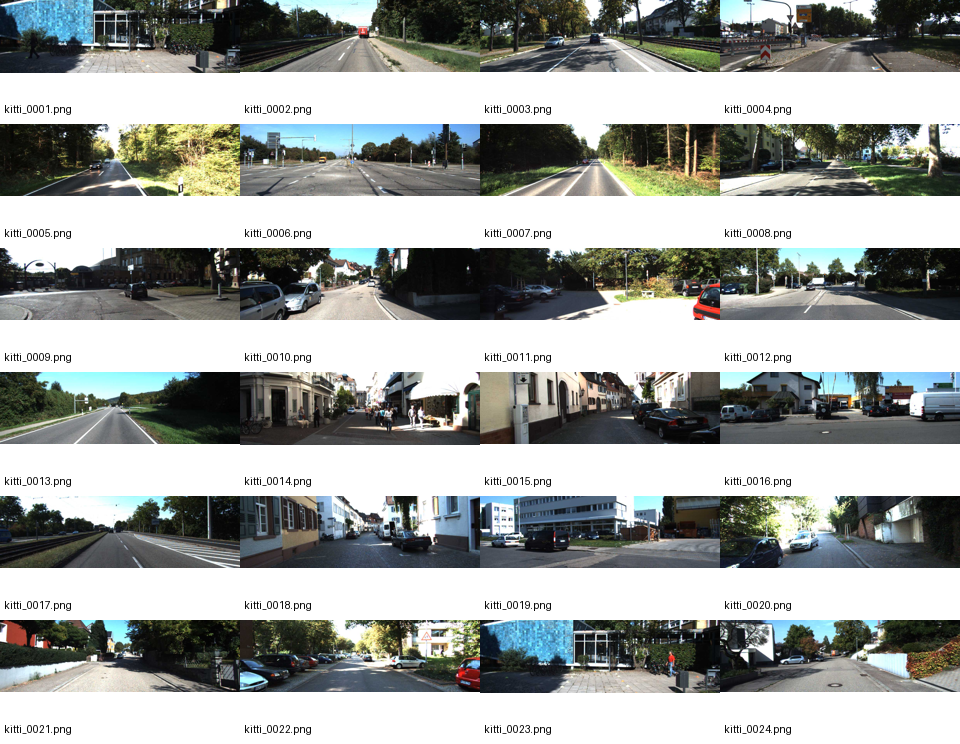

In [ ]:

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
import zipfile
import math
from IPython.display import display

zip_path = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/"
    "kitti_training_subset.zip"
)

with zipfile.ZipFile(zip_path) as z:
    image_names = sorted(
        name for name in z.namelist()
        if Path(name).suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

# Preview the first 24 real images
sample_names = image_names[:24]
thumb_w, thumb_h = 240, 100
label_h = 24
columns = 4
rows = math.ceil(len(sample_names) / columns)

sheet = Image.new(
    "RGB",
    (columns * thumb_w, rows * (thumb_h + label_h)),
    "white",
)
draw = ImageDraw.Draw(sheet)

with zipfile.ZipFile(zip_path) as z:
    for i, name in enumerate(sample_names):
        with z.open(name) as f:
            img = Image.open(f).convert("RGB")
            img.thumbnail((thumb_w, thumb_h))

        x = (i % columns) * thumb_w
        y = (i // columns) * (thumb_h + label_h)

        sheet.paste(img, (x, y))
        draw.text((x + 4, y + thumb_h + 3), Path(name).name, fill="black")

display(sheet)


In [ ]:

from pathlib import Path
from PIL import Image
import random
import json
import torch
from torchvision.transforms import ToTensor
from torchmetrics.image.fid import FrechetInceptionDistance

base = Path("/content/drive/MyDrive/synthetic_driving_dataset")
real_dir = Path("/content/kitti_training_subset")
output_dir = base / "fid_evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

conditions = ["daytime", "night", "rain", "fog"]
extensions = {".jpg", ".jpeg", ".png"}
device = "cuda" if torch.cuda.is_available() else "cpu"
to_tensor = ToTensor()

# Fixed real reference sample, same for every condition
random.seed(42)
real_files = sorted(
    p for p in real_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)
if len(real_files) < 100:
    raise ValueError(f"Need at least 100 real images; found {len(real_files)}")

real_sample = random.sample(real_files, 100)

def load_image(path):
    with Image.open(path) as img:
        img = img.convert("RGB").resize((299, 299))
        return to_tensor(img)

results = {}

for condition in conditions:
    synthetic_dir = base / condition
    synthetic_files = sorted(
        p for p in synthetic_dir.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    )

    if len(synthetic_files) < 25:
        print(f"Skipping {condition}: found only {len(synthetic_files)} images")
        continue

    synthetic_files = synthetic_files[:25]

    fid = FrechetInceptionDistance(
        feature=2048, normalize=True
    ).to(device)

    for path in real_sample:
        image = load_image(path).unsqueeze(0).to(device)
        fid.update(image, real=True)

    for path in synthetic_files:
        image = load_image(path).unsqueeze(0).to(device)
        fid.update(image, real=False)

    score = float(fid.compute().item())
    results[condition] = {
        "fid": score,
        "real_images": len(real_sample),
        "synthetic_images": len(synthetic_files),
        "reference": "100 clear-daytime KITTI images",
    }
    print(
        f"{condition.title():8} FID: {score:.4f} "
        f"(100 real vs {len(synthetic_files)} synthetic)"
    )

    del fid
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

output_path = output_dir / "condition_fid_results.json"
with open(output_path, "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved measured results to:", output_path)


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 206MB/s]


Daytime  FID: 215.7594 (100 real vs 25 synthetic)
Night    FID: 264.2580 (100 real vs 25 synthetic)
Rain     FID: 276.9745 (100 real vs 25 synthetic)
Fog      FID: 282.6892 (100 real vs 25 synthetic)

Saved measured results to: /content/drive/MyDrive/synthetic_driving_dataset/fid_evaluation/condition_fid_results.json


In [ ]:

from google.colab import drive
from pathlib import Path
import zipfile

drive.mount("/content/drive")

zip_path = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/"
    "kitti_training_subset.zip"
)
extract_dir = Path("/content/kitti_training_subset")

if not zip_path.exists():
    raise FileNotFoundError(f"ZIP not found: {zip_path}")

extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extraction complete.")
print("Files/folders at extraction root:")
for item in list(extract_dir.iterdir())[:10]:
    print(item.name)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extraction complete.
Files/folders at extraction root:
kitti_0360.png
kitti_0077.png
kitti_0135.png
kitti_0415.png
kitti_0167.png
kitti_0286.png
kitti_0002.png
kitti_0441.png
kitti_0470.png
kitti_0245.png


In [ ]:

from pathlib import Path

root = Path("/content/kitti_training_subset")
extensions = {".jpg", ".jpeg", ".png"}

real_files = sorted(
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

print("Real images found:", len(real_files))
print("Example paths:")
for path in real_files[:5]:
    print(path)


Real images found: 500
Example paths:
/content/kitti_training_subset/kitti_0001.png
/content/kitti_training_subset/kitti_0002.png
/content/kitti_training_subset/kitti_0003.png
/content/kitti_training_subset/kitti_0004.png
/content/kitti_training_subset/kitti_0005.png


In [ ]:
import importlib.metadata as metadata

for package in ["torch", "diffusers", "torchao", "transformers"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed")

torch: 2.11.0+cu130
diffusers: 0.41.0
torchao: 0.10.0
transformers: 5.20.1


In [ ]:

from diffusers import StableDiffusionPipeline
print("Diffusers import successful!")

Diffusers import successful!


In [ ]:
from pathlib import Path

lora_path = Path(
    "/content/drive/MyDrive/synthetic_driving_dataset/lora_500_steps/checkpoint-500"
)

print("Checkpoint folder exists:", lora_path.exists())
print("LoRA weights file exists:",
      (lora_path / "pytorch_lora_weights.safetensors").exists())

if lora_path.exists():
    print("Files in checkpoint folder:")
    for file in lora_path.iterdir():
        print(file.name)

Checkpoint folder exists: True
LoRA weights file exists: True
Files in checkpoint folder:
pytorch_lora_weights.safetensors
optimizer.bin
scheduler.bin
scaler.pt
random_states_0.pkl


In [ ]:
pipe.load_lora_weights(
    "/content/drive/MyDrive/synthetic_driving_dataset/lora_500_steps/checkpoint-500",
    weight_name="pytorch_lora_weights.safetensors"
)

pipe = pipe.to(device)

print("Trained LoRA weights loaded successfully!")

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Trained LoRA weights loaded successfully!


  0%|          | 0/25 [00:00<?, ?it/s]

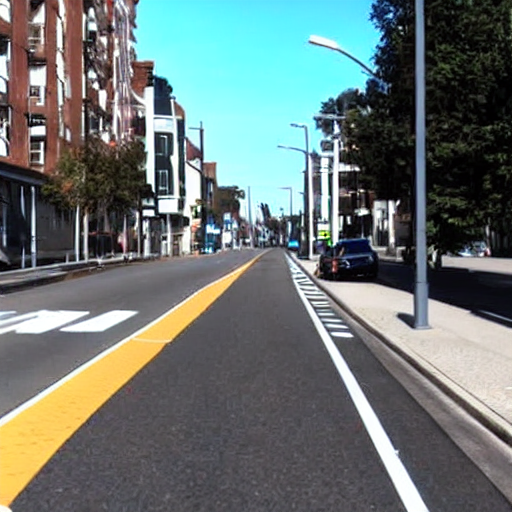

Image saved to: /content/drivesynth_test.png


In [ ]:
from pathlib import Path
from IPython.display import display
import torch

prompt = (
    "realistic autonomous driving dataset, forward-facing dashcam view "
    "of an urban road, cars, lane markings, buildings, daytime, "
    "natural lighting, high detail, realistic photography"
)

generator = torch.Generator(device=device).manual_seed(42)

result = pipe(
    prompt=prompt,
    num_inference_steps=25,
    guidance_scale=7.5,
    width=512,
    height=512,
    generator=generator
)

image = result.images[0]

output_path = Path("/content/drivesynth_test.png")
image.save(output_path)

display(image)
print("Image saved to:", output_path)

  0%|          | 0/25 [00:00<?, ?it/s]

Generated: daytime


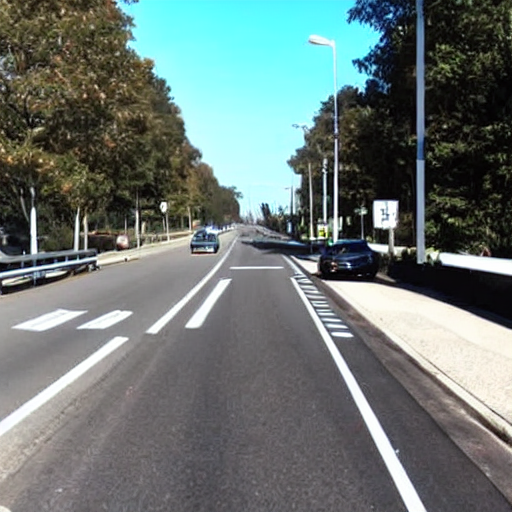

  0%|          | 0/25 [00:00<?, ?it/s]

Generated: night


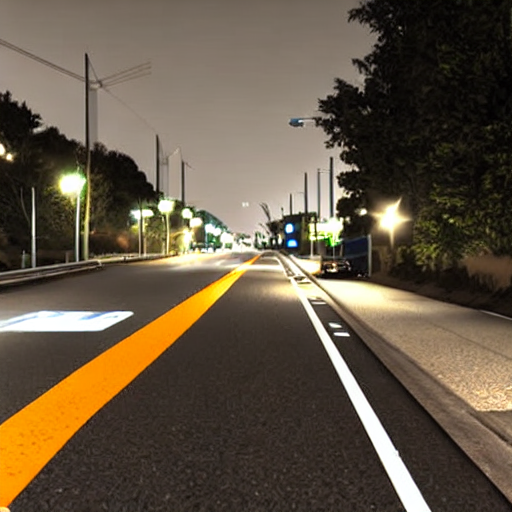

  0%|          | 0/25 [00:00<?, ?it/s]

Generated: rain


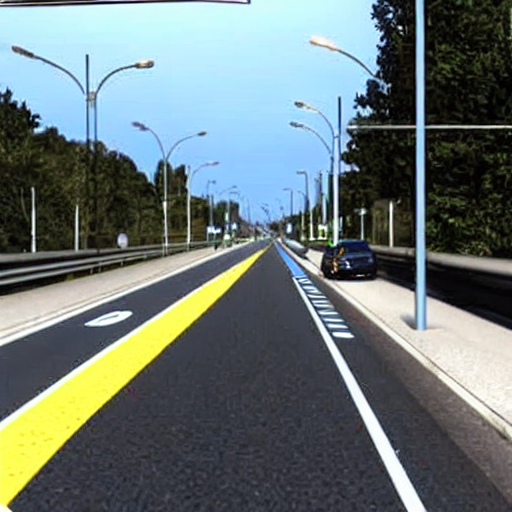

  0%|          | 0/25 [00:00<?, ?it/s]

Generated: fog


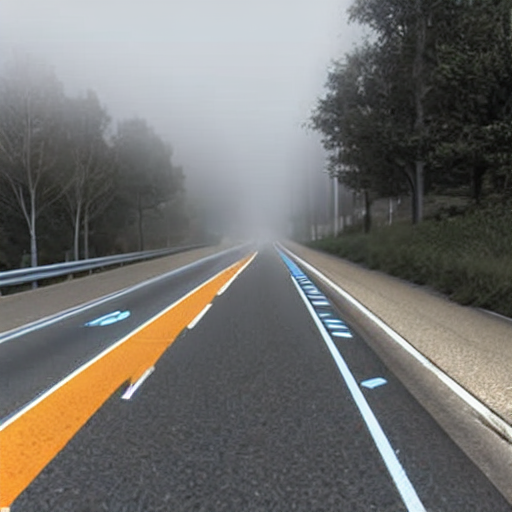

All condition tests saved to: /content/drivesynth_condition_tests


In [ ]:
from pathlib import Path
from IPython.display import display
import torch

output_dir = Path("/content/drivesynth_condition_tests")

conditions = {
    "daytime": "clear daytime, bright natural sunlight",
    "night": "nighttime, dark road, realistic vehicle headlights",
    "rain": "heavy rain, wet road, reflections on the asphalt",
    "fog": "dense fog, low visibility, mist covering the road",
}

for condition, description in conditions.items():
    prompt = (
        "realistic autonomous driving dashcam photograph, "
        "forward-facing view of a road, cars, lane markings, "
        f"{description}, realistic lighting, detailed scene"
    )

    generator = torch.Generator(device=device).manual_seed(42)

    result = pipe(
        prompt=prompt,
        num_inference_steps=25,
        guidance_scale=7.5,
        width=512,
        height=512,
        generator=generator,
    )

    image = result.images[0]
    folder = output_dir / condition
    folder.mkdir(parents=True, exist_ok=True)

    image.save(folder / f"{condition}_test.png")

    print(f"Generated: {condition}")
    display(image)

print("All condition tests saved to:", output_dir)

In [ ]:
import shutil
from google.colab import files

folder = "/content/drivesynth_condition_tests"
zip_path = "/content/drivesynth_condition_tests.zip"

shutil.make_archive(
    "/content/drivesynth_condition_tests",
    "zip",
    folder
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install fastapi uvicorn pyngrok

In [ ]:
from fastapi import FastAPI, Header, HTTPException
from pydantic import BaseModel
from pathlib import Path
from threading import Lock
import torch

app = FastAPI(title="DriveSynth AI API")
generation_lock = Lock()

class GenerateRequest(BaseModel):
    prompt: str
    condition: str = "daytime"
    count: int = 1

@app.get("/")
def home():
    return {"status": "DriveSynth AI model is running"}

@app.post("/generate")
def generate(
    request: GenerateRequest,
    x_api_token: str = Header(default="")
):
    if not secrets.compare_digest(x_api_token, DRIVESYNTH_API_TOKEN):
        raise HTTPException(status_code=401, detail="Invalid API token")

    if request.condition not in {"daytime", "night", "rain", "fog"}:
        raise HTTPException(status_code=400, detail="Unsupported condition")

    if not 1 <= request.count <= 4:
        raise HTTPException(status_code=400, detail="Count must be between 1 and 4")

    descriptions = {
        "daytime": "daytime, natural sunlight",
        "night": "nighttime, realistic vehicle headlights",
        "rain": "rainy road, wet asphalt, reflections",
        "fog": "foggy road, mist, reduced visibility",
    }

    prompt = (
        "realistic autonomous driving dashcam photograph, "
        "forward-facing road view, cars, lane markings, "
        + descriptions[request.condition]
        + ", "
        + request.prompt
    )

    output_dir = Path("/content/drivesynth_api_images")
    output_dir.mkdir(parents=True, exist_ok=True)
    generated = []

    with generation_lock:
        for i in range(request.count):
            generator = torch.Generator(device=device).manual_seed(100 + i)
            result = pipe(
                prompt=prompt,
                num_inference_steps=25,
                guidance_scale=7.5,
                width=512,
                height=512,
                generator=generator,
            )

            filename = f"{request.condition}_{i}_{secrets.token_hex(4)}.png"
            result.images[0].save(output_dir / filename)
            generated.append(filename)

    return {
        "status": "success",
        "condition": request.condition,
        "count": len(generated),
        "images": generated,
    }

In [ ]:
import uvicorn
import threading

def run_server():
    uvicorn.run(app, host="0.0.0.0", port=8000, log_level="info")

server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()

print("DriveSynth API server is starting...")

DriveSynth API server is starting...


In [ ]:
import requests

response = requests.get("http://127.0.0.1:8000/", timeout=10)

print("Status code:", response.status_code)
print("Response:", response.json())

INFO:     127.0.0.1:36672 - "GET / HTTP/1.1" 200 OK
Status code: 200
Response: {'status': 'DriveSynth AI model is running'}


In [ ]:
import secrets

DRIVESYNTH_API_TOKEN = secrets.token_urlsafe(32)
print("Your temporary API token:")
print(DRIVESYNTH_API_TOKEN)

Your temporary API token:
NmX8Vk8f_2cV0v1-p2n1zp4_TtKs4fEUomPC0RrV8g8


In [ ]:
import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
lora_path = "/content/drive/MyDrive/synthetic_driving_dataset/lora_500_steps/checkpoint-500"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype,
    use_safetensors=True,
)

pipe.load_lora_weights(
    lora_path,
    weight_name="pytorch_lora_weights.safetensors",
)

pipe = pipe.to(device)

print("DriveSynth model and LoRA loaded successfully!")
print("Device:", device)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


DriveSynth model and LoRA loaded successfully!
Device: cuda


In [4]:
import secrets
from pathlib import Path
from threading import Lock

import torch
from fastapi import FastAPI, Header, HTTPException
from fastapi.responses import FileResponse
from pydantic import BaseModel

app = FastAPI(title="DriveSynth AI API")
generation_lock = Lock()
output_dir = Path("/content/drivesynth_api_images")
output_dir.mkdir(parents=True, exist_ok=True)

# Paste your previously copied token between the quotes.
DRIVESYNTH_API_TOKEN = "NmX8Vk8f_2cV0v1-p2n1zp4_TtKs4fEUomPC0RrV8g8"

class GenerateRequest(BaseModel):
    prompt: str
    condition: str = "daytime"
    count: int = 1

def verify_token(token: str):
    if not secrets.compare_digest(token, DRIVESYNTH_API_TOKEN):
        raise HTTPException(status_code=401, detail="Invalid API token")

@app.get("/")
def home():
    return {"status": "DriveSynth AI model is running"}

@app.post("/generate")
def generate(
    request: GenerateRequest,
    x_api_token: str = Header(default=""),
):
    verify_token(x_api_token)

    if request.condition not in {"daytime", "night", "rain", "fog"}:
        raise HTTPException(status_code=400, detail="Unsupported condition")
    if not 1 <= request.count <= 4:
        raise HTTPException(status_code=400, detail="Count must be between 1 and 4")
    if not request.prompt.strip() or len(request.prompt) > 500:
        raise HTTPException(status_code=400, detail="Prompt must be 1–500 characters")

    descriptions = {
        "daytime": "daytime, natural sunlight",
        "night": "nighttime, vehicle headlights",
        "rain": "rainy road, wet asphalt, reflections",
        "fog": "foggy road, mist, reduced visibility",
    }

    prompt = (
        "realistic autonomous driving dashcam photograph, "
        "forward-facing road view, cars, lane markings, "
        f"{descriptions[request.condition]}, {request.prompt}"
    )

    generated = []
    with generation_lock:
        for _ in range(request.count):
            result = pipe(
                prompt=prompt,
                num_inference_steps=25,
                guidance_scale=7.5,
                width=512,
                height=512,
            )
            filename = f"{request.condition}_{secrets.token_hex(8)}.png"
            result.images[0].save(output_dir / filename)
            generated.append(filename)

    return {
        "status": "success",
        "condition": request.condition,
        "count": len(generated),
        "images": [f"/images/{name}" for name in generated],
    }

@app.get("/images/{filename}")
def get_image(filename: str, x_api_token: str = Header(default="")):
    verify_token(x_api_token)

    # Only serve PNGs in the designated output folder.
    if Path(filename).name != filename or not filename.endswith(".png"):
        raise HTTPException(status_code=400, detail="Invalid filename")

    image_path = output_dir / filename
    if not image_path.is_file():
        raise HTTPException(status_code=404, detail="Image not found")

    return FileResponse(image_path, media_type="image/png")

print("Protected DriveSynth API is ready.")

Protected DriveSynth API is ready.


In [5]:
import uvicorn
import threading

def run_server():
    uvicorn.run(app, host="0.0.0.0", port=8000, log_level="info")

server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()

print("DriveSynth API server starting...")

DriveSynth API server starting...


In [6]:
import requests

response = requests.get("http://127.0.0.1:8000/", timeout=10)
print("Status:", response.status_code)
print("Response:", response.json())

INFO:     127.0.0.1:32772 - "GET / HTTP/1.1" 200 OK
Status: 200
Response: {'status': 'DriveSynth AI model is running'}


In [7]:
import requests

url = "http://127.0.0.1:8000/generate"

headers = {
    "X-API-Token": DRIVESYNTH_API_TOKEN
}

payload = {
    "prompt": "urban road with cars and clear lane markings",
    "condition": "daytime",
    "count": 1
}

response = requests.post(
    url,
    headers=headers,
    json=payload,
    timeout=300
)

print("Status:", response.status_code)
print("Response:", response.json())

INFO:     127.0.0.1:32774 - "POST /generate HTTP/1.1" 500 Internal Server Error


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 422, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        self.scope, self.receive, self.send
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/middleware/proxy_headers.py", line 63, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastapi/applications.py", line 1163, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/starlette/applications.py", line 96, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/starlette/middleware/errors.py", line 186, i

Status: 500


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [8]:
import requests
from IPython.display import display
from PIL import Image
from io import BytesIO

image_path = response.json()["images"][0]
image_url = "http://127.0.0.1:8000" + image_path

image_response = requests.get(
    image_url,
    headers={"X-API-Token": DRIVESYNTH_API_TOKEN},
    timeout=30,
)

print("Image status:", image_response.status_code)
print("Content type:", image_response.headers.get("content-type"))

image = Image.open(BytesIO(image_response.content))
display(image)

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [2]:
from getpass import getpass
from pyngrok import ngrok

ngrok_token = getpass("Paste your token here:")
ngrok.set_auth_token(ngrok_token)

print("ngrok authentication configured.")

ModuleNotFoundError: No module named 'pyngrok'

In [1]:
from pyngrok import ngrok

public_url = ngrok.connect(8000, "http").public_url
print("DriveSynth API URL:", public_url)

ModuleNotFoundError: No module named 'pyngrok'